In [53]:
import matplotlib.pyplot as plt
import scienceplots
import numpy as np 
import pandas as pd
import os 

# Intensity reconstruction

In [54]:
os.listdir()
intensity_train_csv = pd.read_csv(os.path.join("analysis", "retina_train_saliency.csv"))

intensity_train_csv.columns

Index(['Step', 'FIRE_saliency_seq=50_gk5_20251201_014614 - train_loss_epoch',
       'FIRE_saliency_seq=50_gk5_20251201_014614 - train_loss_epoch__MIN',
       'FIRE_saliency_seq=50_gk5_20251201_014614 - train_loss_epoch__MAX',
       'FIREnetwork_DVS_seq=50 - train_loss_epoch',
       'FIREnetwork_DVS_seq=50 - train_loss_epoch__MIN',
       'FIREnetwork_DVS_seq=50 - train_loss_epoch__MAX',
       'FIRE_saliency_p2=1.0_20251128_082440 - train_loss_epoch',
       'FIRE_saliency_p2=1.0_20251128_082440 - train_loss_epoch__MIN',
       'FIRE_saliency_p2=1.0_20251128_082440 - train_loss_epoch__MAX',
       'FIREnetwork_DVS2_seq=30 - train_loss_epoch',
       'FIREnetwork_DVS2_seq=30 - train_loss_epoch__MIN',
       'FIREnetwork_DVS2_seq=30 - train_loss_epoch__MAX'],
      dtype='object')

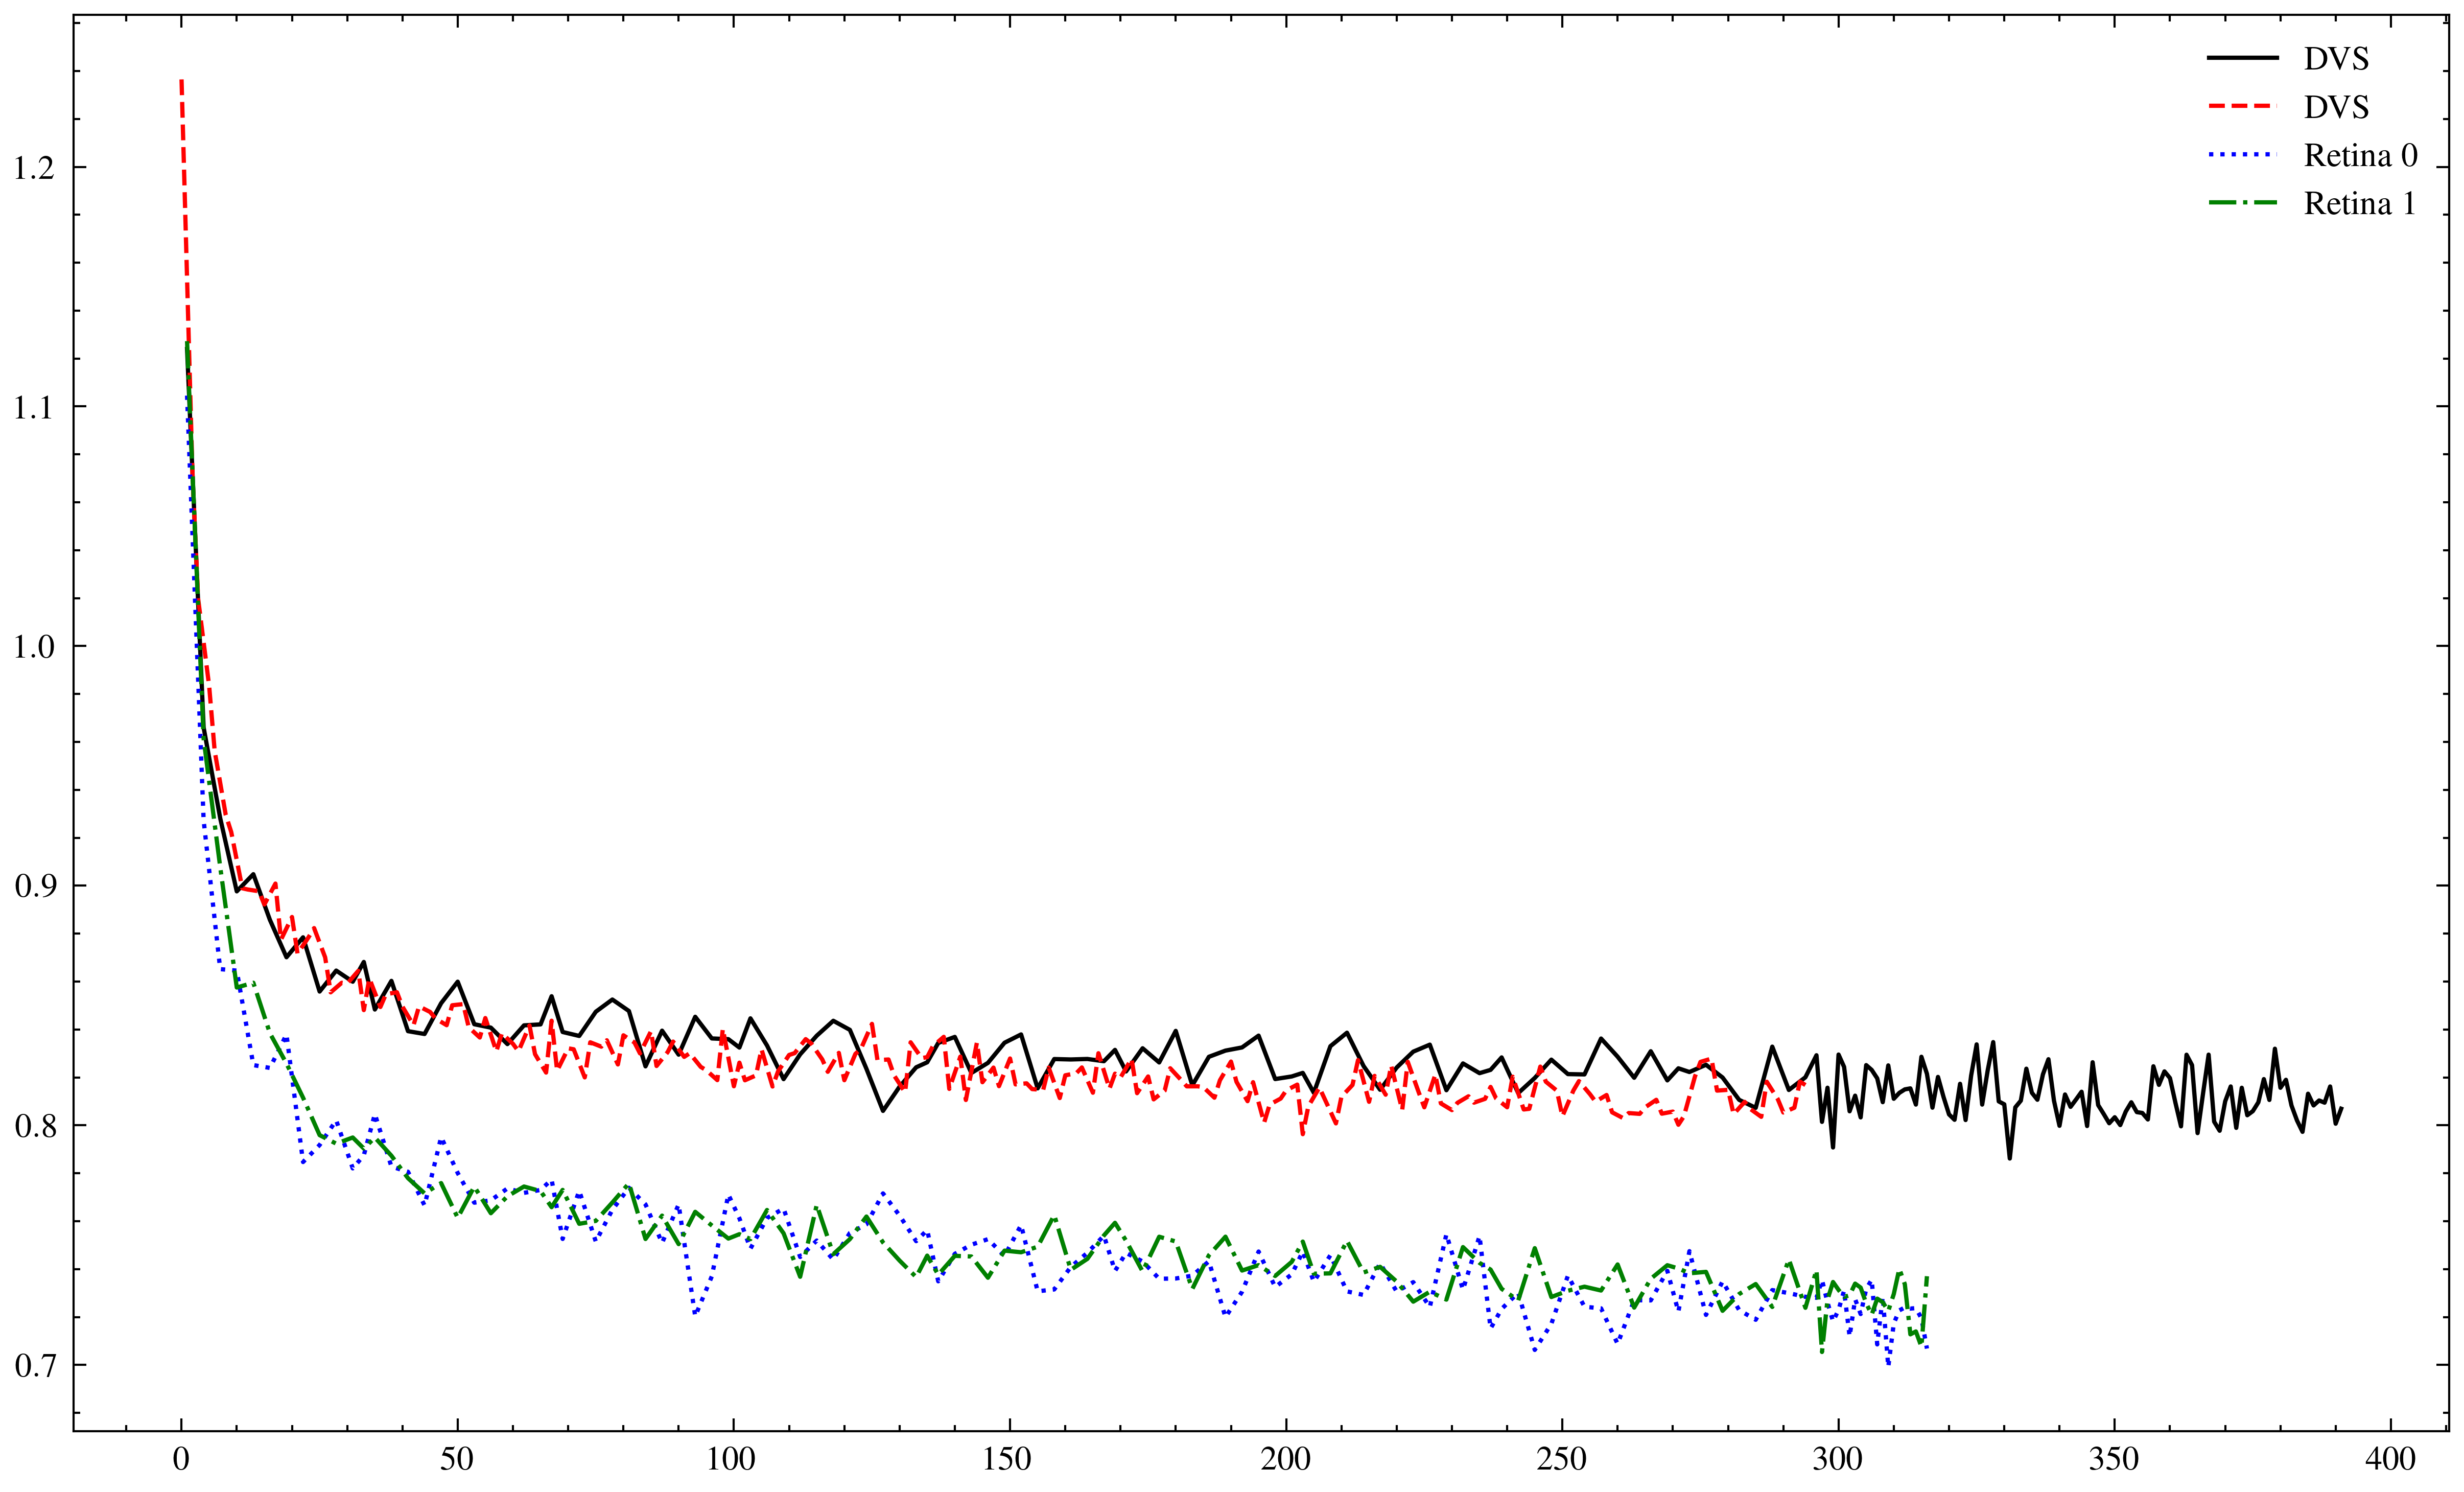

In [55]:
dvs_group_train = ['FIREnetwork_DVS2_seq=30 - train_loss_epoch',
                   'FIREnetwork_DVS_seq=50 - train_loss_epoch']

retina_group_train = ['FIRE_saliency_p2=1.0_20251128_082440 - train_loss_epoch',
                      'FIRE_saliency_seq=50_gk5_20251201_014614 - train_loss_epoch']


plt.figure(figsize=(10, 6))

for col in dvs_group_train:
    data = intensity_train_csv[col]
    plt.plot(data[data.notna()], label="DVS")

for i, col in enumerate(retina_group_train):
    data = intensity_train_csv[col]
    plt.plot(data[data.notna()], label=f"Retina {i}")

plt.legend()
plt.show()

Plot saved as saliency_training_loss.png


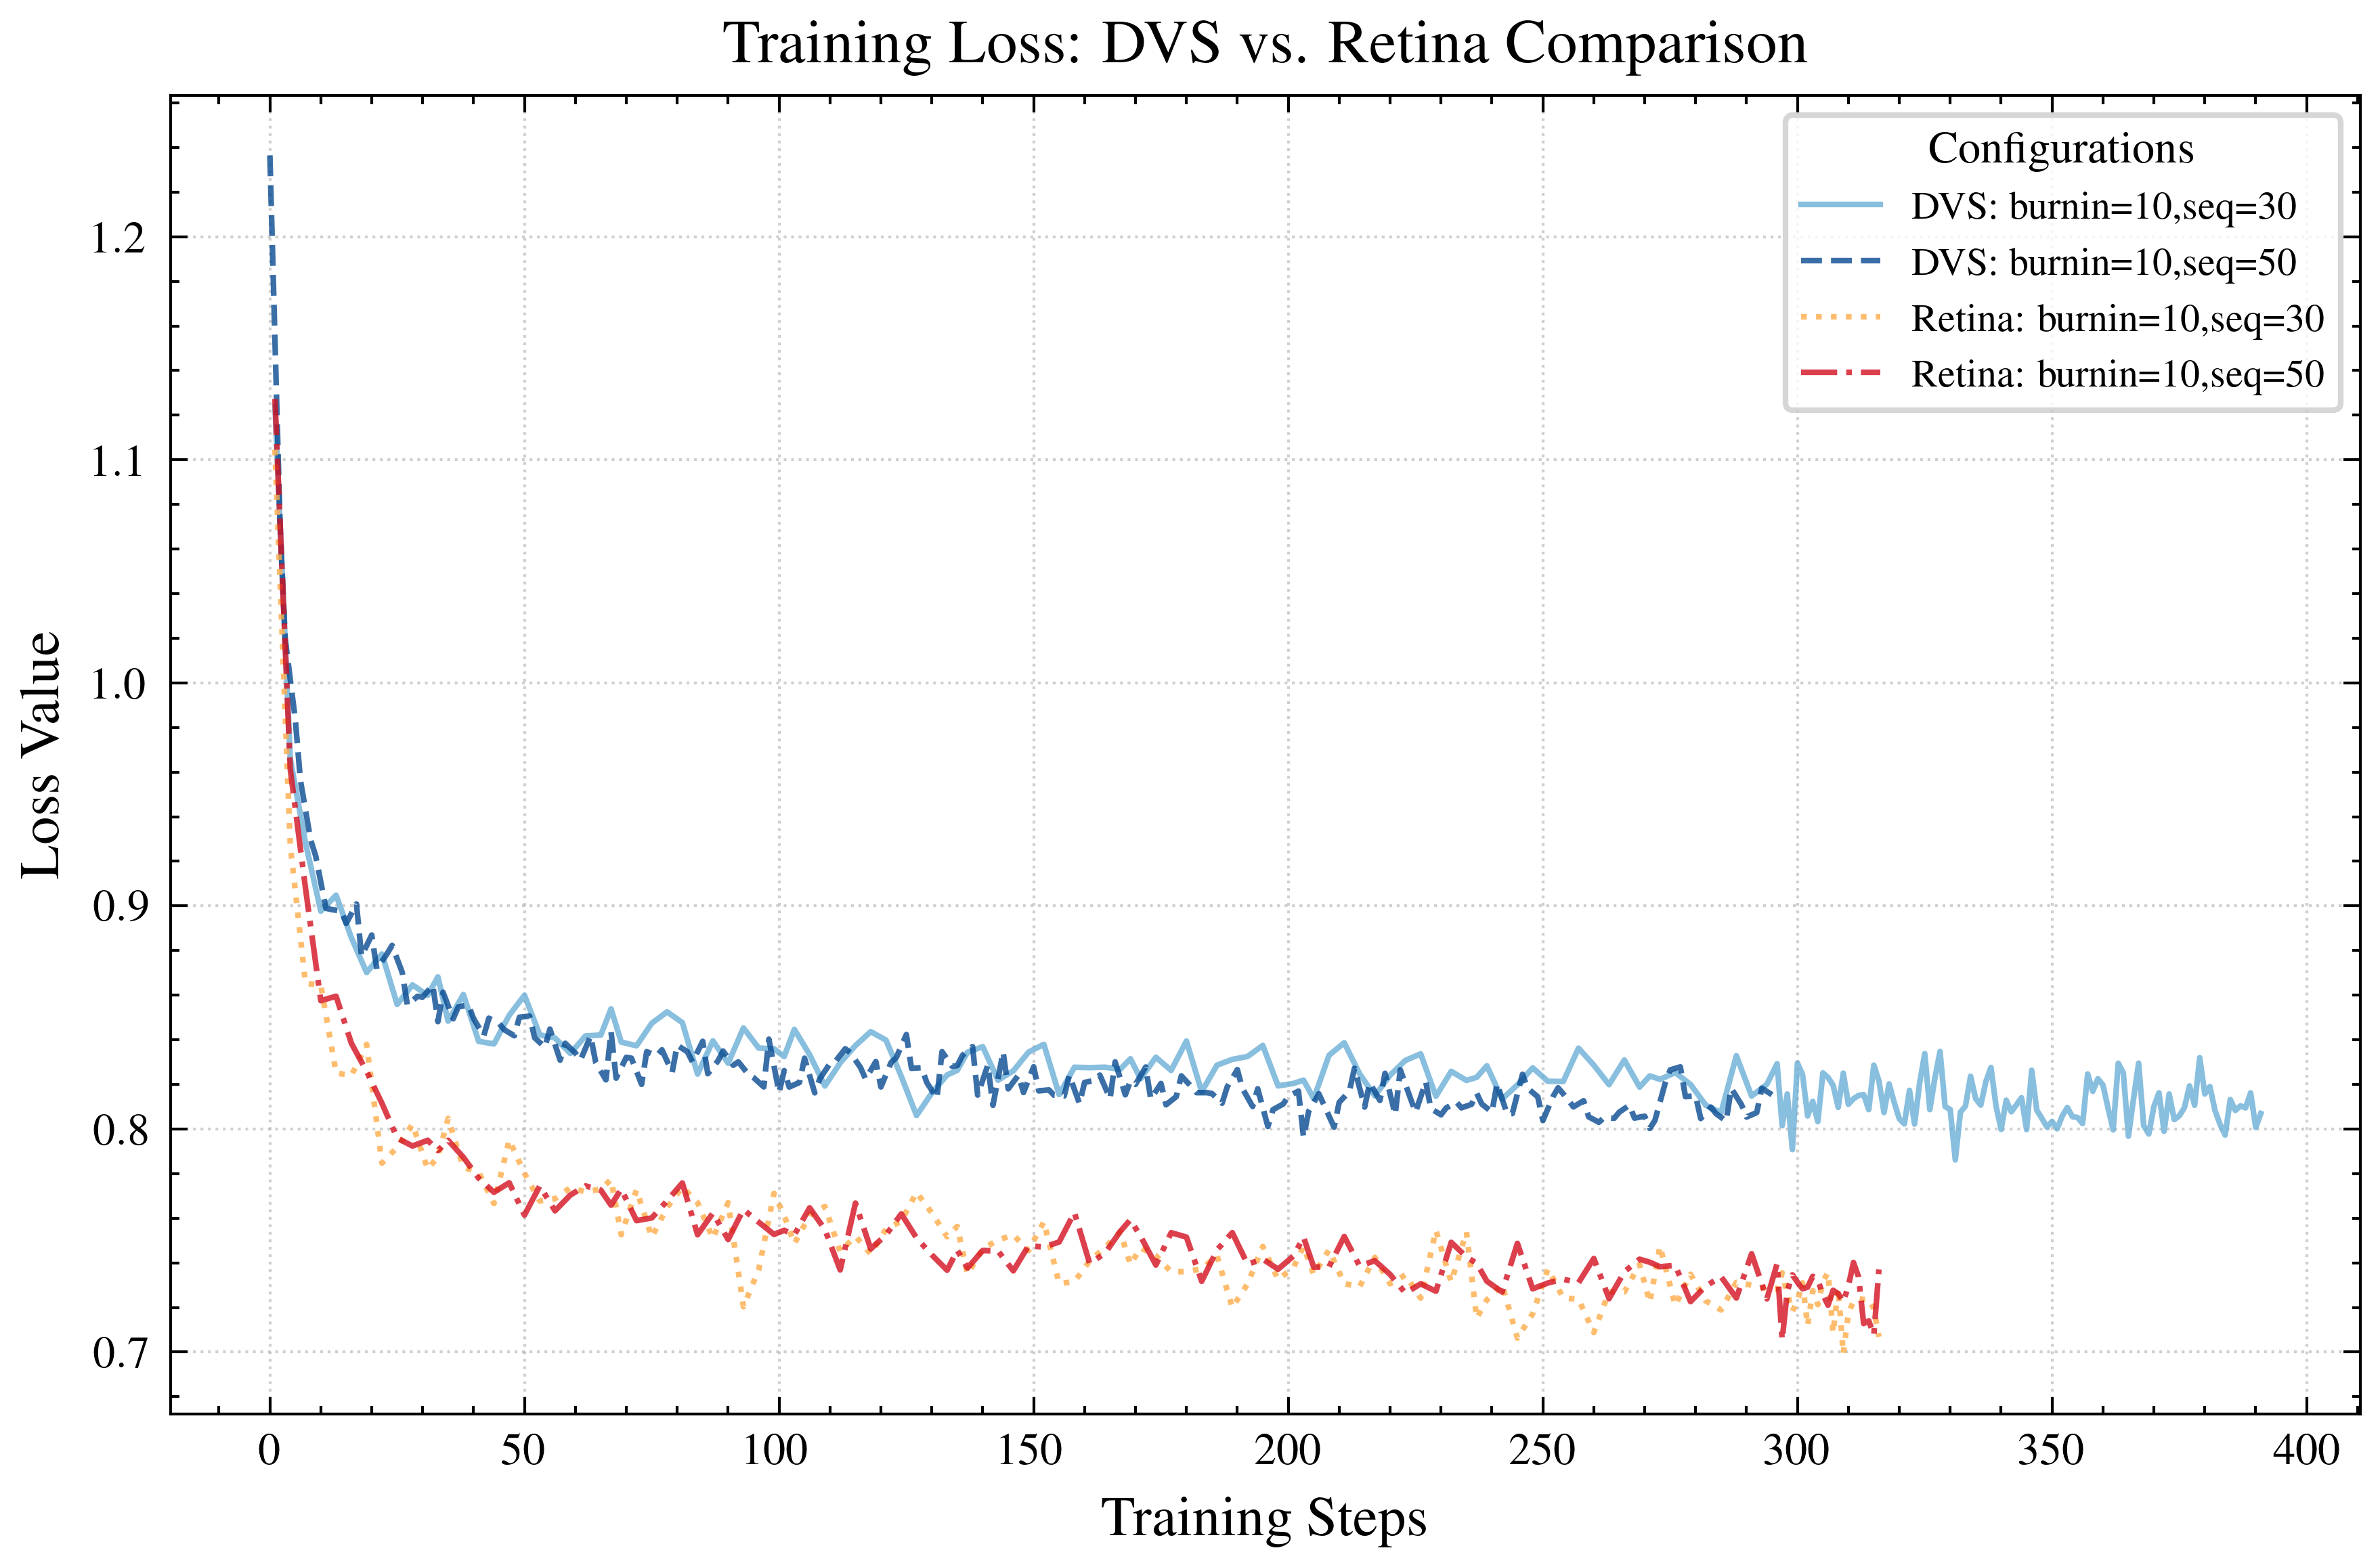

In [63]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

plt.style.use(['science', 'ieee']) 

dvs_label_names = ["burnin=10,seq=30",
                   "burnin=10,seq=50"]
retina_label_names = ["burnin=10,seq=30",
                   "burnin=10,seq=50"]

def plot_loss_data(df, dvs_group, dvs_labels, 
                   retina_group, retina_labels, 
                   is_train, smoothing=0.0):
    fig, ax = plt.subplots(figsize=(6, 4))
    
    prefix = "Training" if is_train else "Validation"
    
    # 1. Generate color palettes
    # Using Blues for DVS and YlOrRd for Retina
    # We take a subset of the colormap (e.g., 0.4 to 0.9) to avoid colors that are too light
    dvs_colors = plt.cm.Blues(np.linspace(0.5, 0.9, len(dvs_group)))
    retina_colors = plt.cm.YlOrRd(np.linspace(0.4, 0.8, len(retina_group)))

    # 2. Plot DVS Group
    for i, col in enumerate(dvs_group):
        data = df[col].dropna()
        label = dvs_labels[i]
        color = dvs_colors[i]
        
        if smoothing > 0:
            smoothed = data.ewm(alpha=1-smoothing).mean()
            ax.plot(data.index, smoothed, label=f"DVS: {label}", 
                    color=color, linewidth=1.2)
            # Faint raw data line
            ax.plot(data.index, data, color=color, linewidth=0.8, alpha=0.25)
        else:
            ax.plot(data.index, data, label=f"DVS: {label}", 
                    color=color, linewidth=1.0, alpha=0.8)

    # 3. Plot Retina Group
    for i, col in enumerate(retina_group):
        data = df[col].dropna()
        label = retina_labels[i]
        color = retina_colors[i]
        
        if smoothing > 0:
            smoothed = data.ewm(alpha=1-smoothing).mean()
            ax.plot(data.index, smoothed, label=f"Retina: {label}", 
                    color=color, linewidth=1.2)
            # Faint raw data line
            ax.plot(data.index, data, color=color, linewidth=0.8, alpha=0.15)
        else:
            ax.plot(data.index, data, label=f"Retina: {label}", 
                    color=color, linewidth=1.0, alpha=0.8)

    # 4. Polish the graph
    ax.set_xlabel(f'{prefix} Steps', fontsize=10)
    ax.set_ylabel(r'Loss Value', fontsize=10)
    ax.set_title(f'{prefix} Loss: DVS vs. Retina Comparison', fontsize=11, fontweight='bold')
    
    # Legend - placing it slightly outside or in a clear spot
    ax.legend(title='Configurations', fontsize=7, title_fontsize=8, 
              loc='upper right', frameon=True)
    
    ax.grid(True, linestyle=':', alpha=0.6)
    
    # Optional: use log scale if loss values vary by orders of magnitude
    # ax.set_yscale('log')
    
    plt.tight_layout()
    
    # Save with high DPI for publications
    file_name = f'saliency_{prefix.lower()}_loss.png'
    plt.savefig(file_name, dpi=300, bbox_inches='tight')
    print(f"Plot saved as {file_name}")
    plt.show()

# Usage with your dataframe
plot_loss_data(intensity_train_csv, 
               dvs_group_train, dvs_label_names,
               retina_group_train, retina_label_names, is_train=True, smoothing=0.0)

In [64]:
dvs_train = intensity_train_csv[dvs_group_train]
retina_train = intensity_train_csv[retina_group_train]

print("intensity DVS train min :", np.min(intensity_train_csv[dvs_group_train]))
print("intensity retina train min :", np.min(intensity_train_csv[retina_group_train]))

intensity DVS train min : 0.7861435057388412
intensity retina train min : 0.6991305100145163


In [65]:
import pandas as pd
import numpy as np

N = 20

def get_final_metrics(df, columns, n=5):
    """
    Extracts the average of the last N non-NaN values for a list of columns.
    """
    results = {}
    for col in columns:
        # 1. Drop NaNs to get the actual sequence of recordings
        clean_series = df[col].dropna()
        
        # 2. Take the last N values
        last_n_values = clean_series.tail(n)
        
        # 3. Calculate mean
        results[col] = last_n_values.mean()
        
    return results


dvs_averages = get_final_metrics(intensity_train_csv, dvs_group_train, n=N)
retina_averages = get_final_metrics(intensity_train_csv, retina_group_train, n=N)

# Displaying results clearly
print(f"--- Final Average Loss (Last {N} steps) ---")
print("\nDVS Group:")
for name, val in dvs_averages.items():
    print(f"{name}: {val:.4f}")


print("\nRetina Group:")
for name, val in retina_averages.items():
    print(f"{name}: {val:.4f}")

--- Final Average Loss (Last 20 steps) ---

DVS Group:
FIREnetwork_DVS2_seq=30 - train_loss_epoch: 0.8102
FIREnetwork_DVS_seq=50 - train_loss_epoch: 0.8115

Retina Group:
FIRE_saliency_p2=1.0_20251128_082440 - train_loss_epoch: 0.7218
FIRE_saliency_seq=50_gk5_20251201_014614 - train_loss_epoch: 0.7260


# Validation 

In [66]:
dvs_group_val = ['FIREnetwork_DVS2_seq=30 - val_loss_epoch',
                   'FIREnetwork_DVS_seq=50 - val_loss_epoch']

retina_group_val = ['FIRE_saliency_p2=1.0_20251128_082440 - val_loss_epoch',
                      'FIRE_saliency_seq=50_gk5_20251201_014614 - val_loss_epoch']
os.listdir()
intensity_val_csv = pd.read_csv(os.path.join("analysis", "retina_val_saliency.csv"))
print(intensity_val_csv.columns)

Index(['Step', 'FIRE_saliency_seq=50_gk5_20251201_014614 - val_loss_epoch',
       'FIRE_saliency_seq=50_gk5_20251201_014614 - val_loss_epoch__MIN',
       'FIRE_saliency_seq=50_gk5_20251201_014614 - val_loss_epoch__MAX',
       'FIREnetwork_DVS_seq=50 - val_loss_epoch',
       'FIREnetwork_DVS_seq=50 - val_loss_epoch__MIN',
       'FIREnetwork_DVS_seq=50 - val_loss_epoch__MAX',
       'FIRE_saliency_p2=1.0_20251128_082440 - val_loss_epoch',
       'FIRE_saliency_p2=1.0_20251128_082440 - val_loss_epoch__MIN',
       'FIRE_saliency_p2=1.0_20251128_082440 - val_loss_epoch__MAX',
       'FIREnetwork_DVS2_seq=30 - val_loss_epoch',
       'FIREnetwork_DVS2_seq=30 - val_loss_epoch__MIN',
       'FIREnetwork_DVS2_seq=30 - val_loss_epoch__MAX'],
      dtype='object')


Plot saved as saliency_validation_loss.png


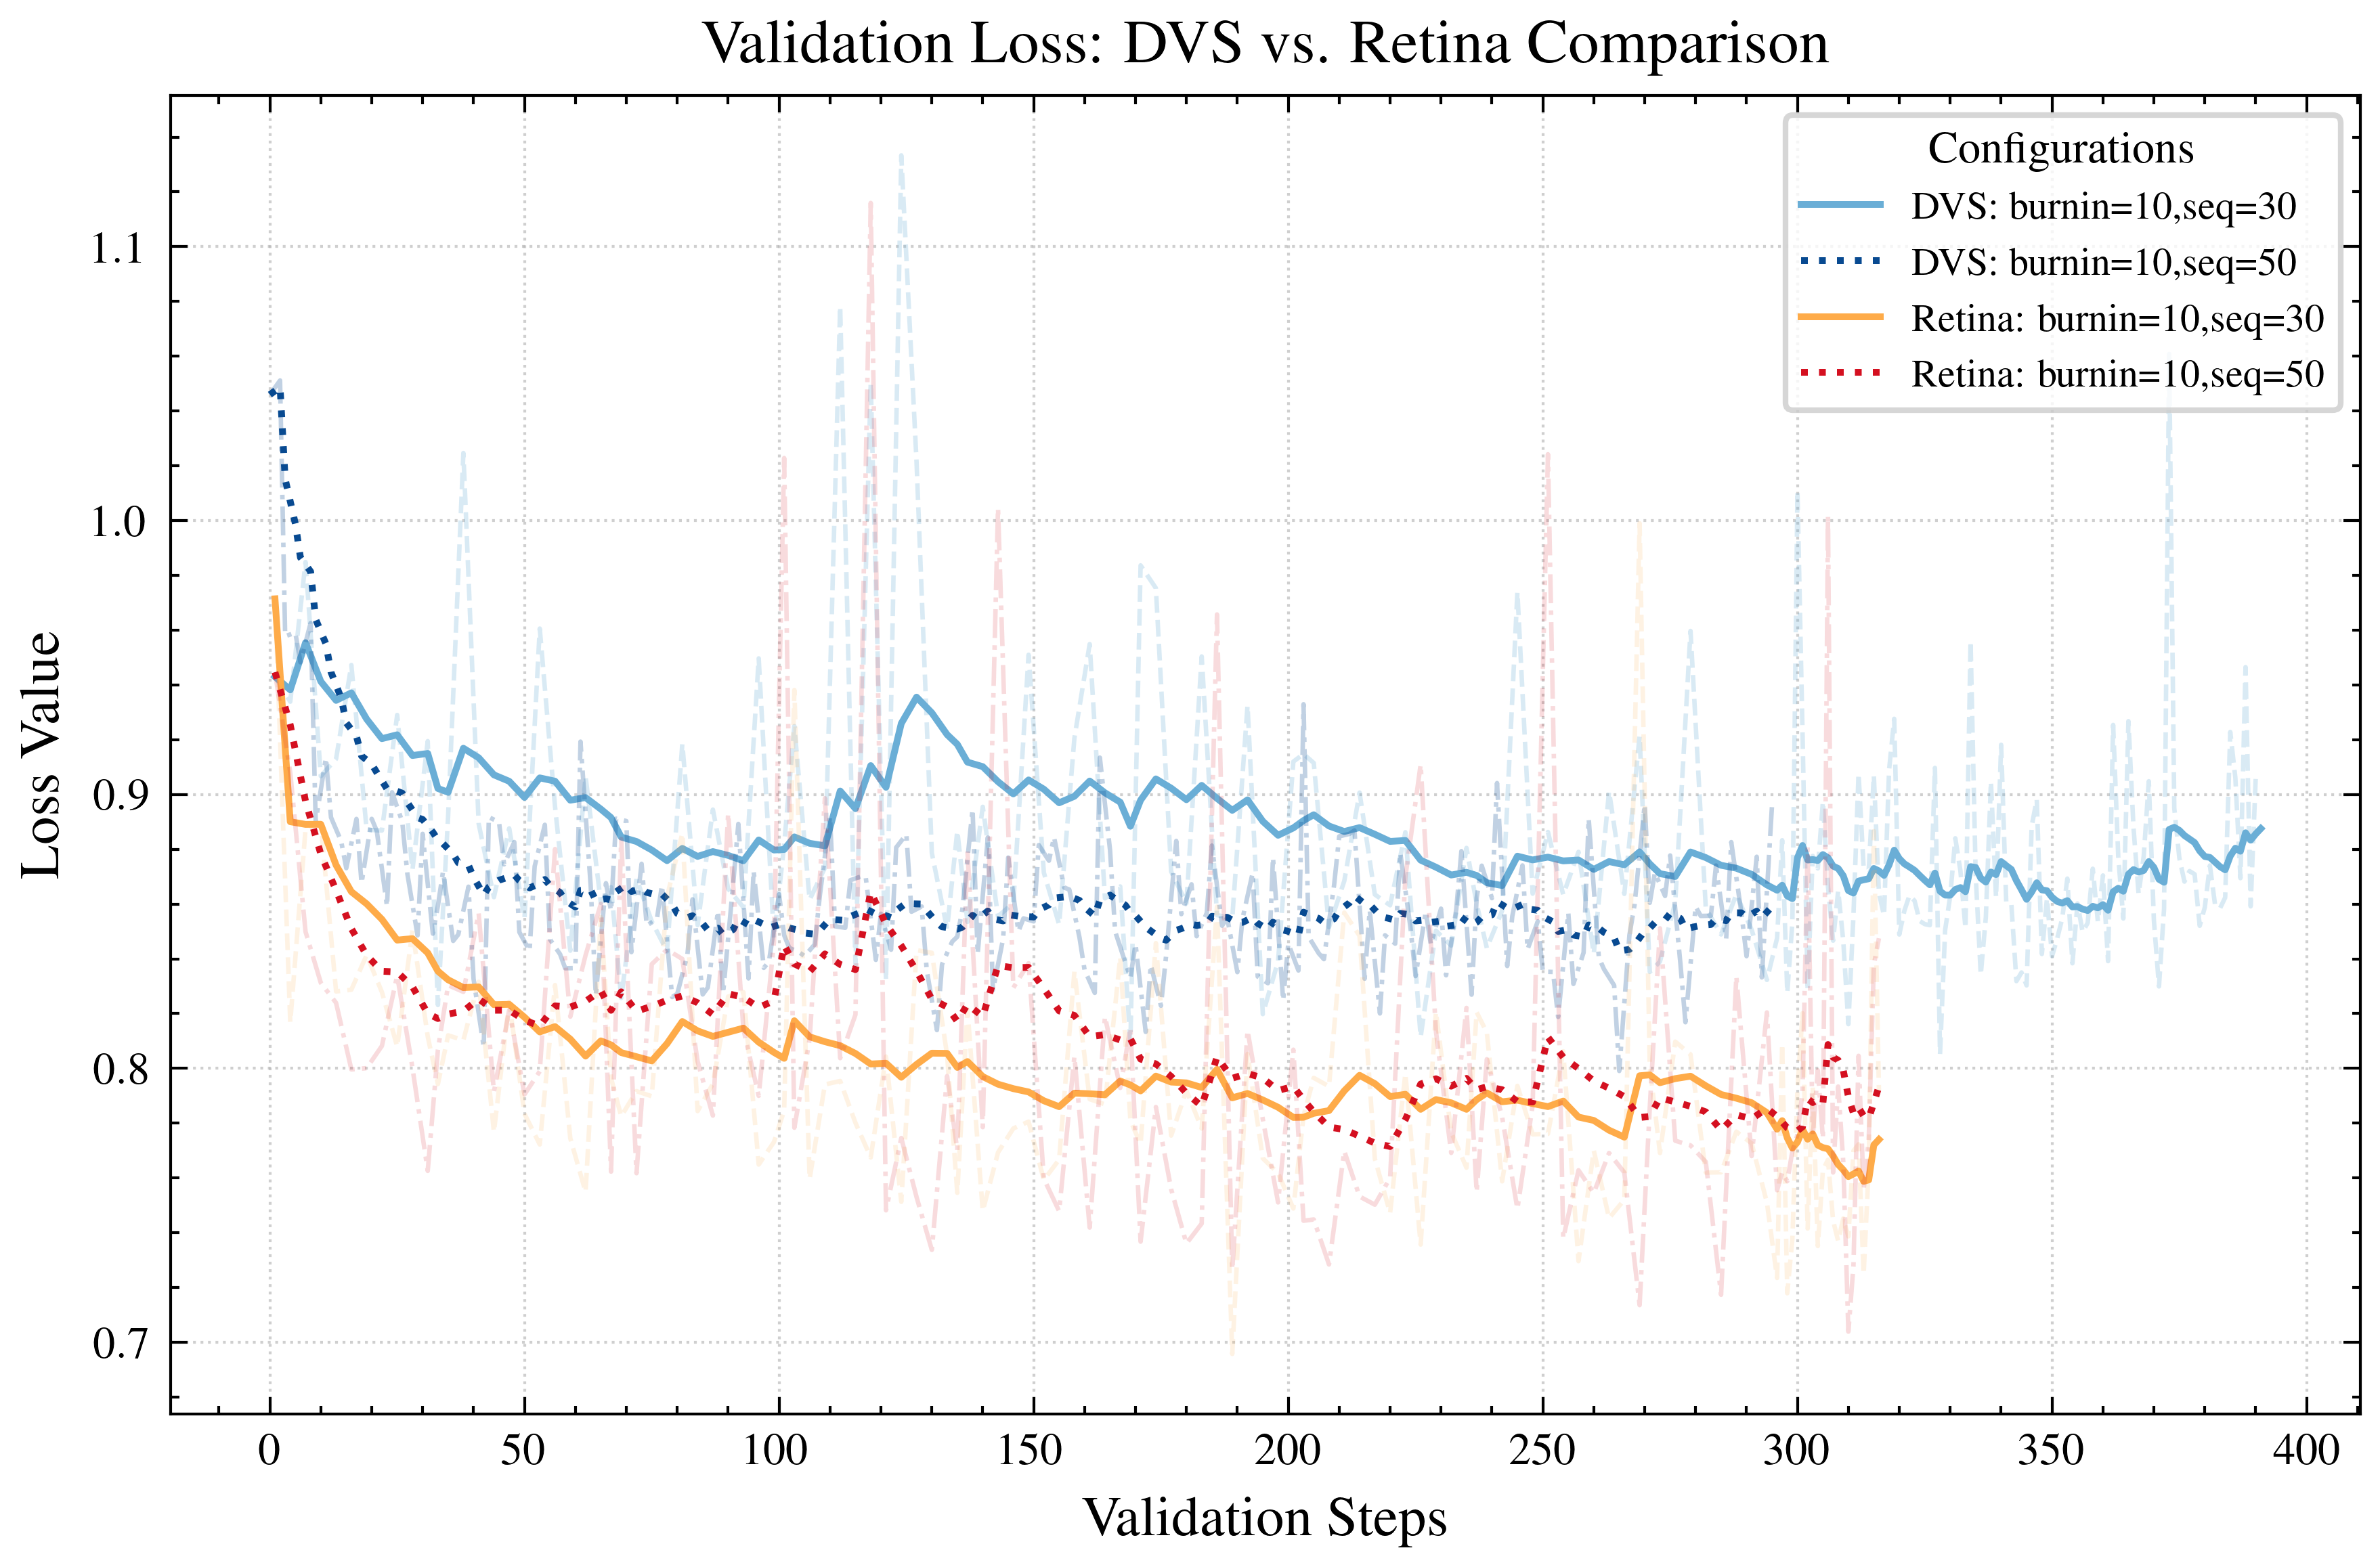

In [67]:
plot_loss_data(intensity_val_csv, 
               dvs_group_val, dvs_label_names,
               retina_group_val, retina_label_names, smoothing=0.9, is_train=False)

In [68]:
print(np.min(intensity_val_csv[dvs_group_val]))
print(np.min(intensity_val_csv[retina_group_val]))

0.7990590397800718
0.6957454161210493


In [69]:
dvs_averages = get_final_metrics(intensity_val_csv, dvs_group_val, n=N)
retina_averages = get_final_metrics(intensity_val_csv, retina_group_val, n=N)

# Displaying results clearly
print(f"--- Final Average Loss (Last {N} steps) ---")
print("\nDVS Group:")
for name, val in dvs_averages.items():
    print(f"{name}: {val:.4f}")


print("\nRetina Group:")
for name, val in retina_averages.items():
    print(f"{name}: {val:.4f}")

--- Final Average Loss (Last 20 steps) ---

DVS Group:
FIREnetwork_DVS2_seq=30 - val_loss_epoch: 0.8891
FIREnetwork_DVS_seq=50 - val_loss_epoch: 0.8606

Retina Group:
FIRE_saliency_p2=1.0_20251128_082440 - val_loss_epoch: 0.7676
FIRE_saliency_seq=50_gk5_20251201_014614 - val_loss_epoch: 0.7931


# Ablation studies

<>:31: SyntaxWarning: invalid escape sequence '\%'
<>:51: SyntaxWarning: invalid escape sequence '\%'
<>:58: SyntaxWarning: invalid escape sequence '\%'
<>:31: SyntaxWarning: invalid escape sequence '\%'
<>:51: SyntaxWarning: invalid escape sequence '\%'
<>:58: SyntaxWarning: invalid escape sequence '\%'
/tmp/ipykernel_98907/21380770.py:31: SyntaxWarning: invalid escape sequence '\%'
  label='Occupancy (\%)', zorder=3)
/tmp/ipykernel_98907/21380770.py:51: SyntaxWarning: invalid escape sequence '\%'
  ax2.annotate(f'{txt:.2f}\%',
/tmp/ipykernel_98907/21380770.py:58: SyntaxWarning: invalid escape sequence '\%'
  ax2.set_ylabel('Grid Occupancy (\%)', color='C1')


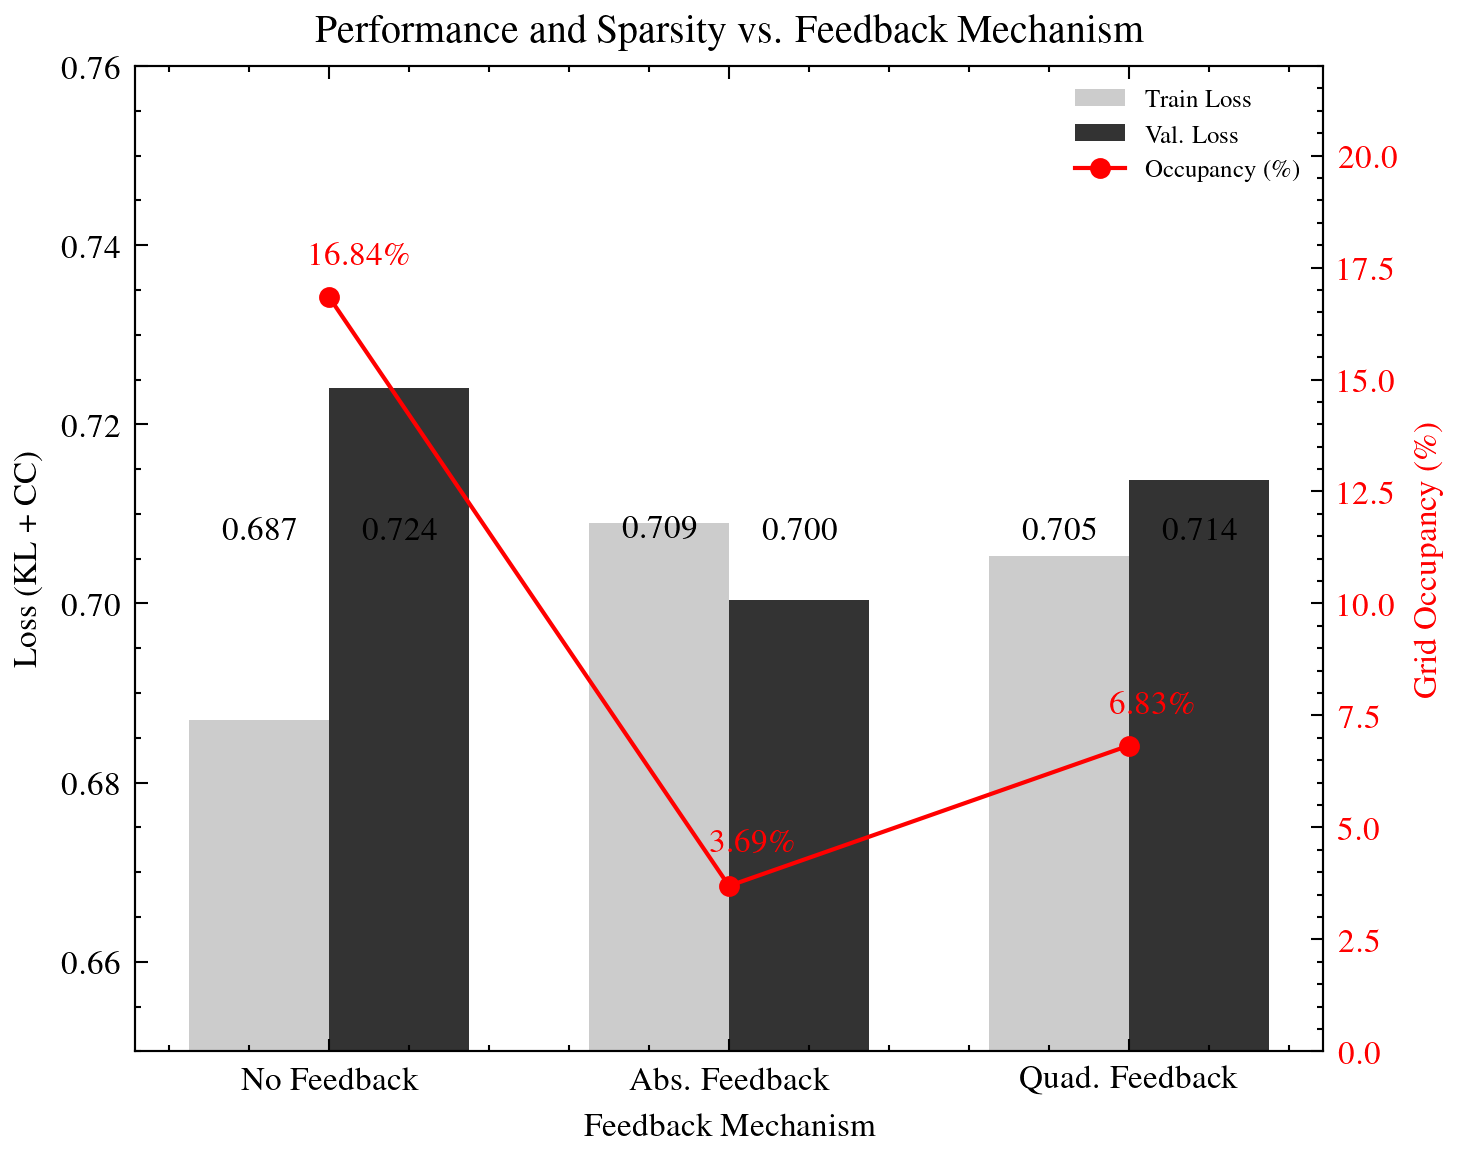

In [ ]:
import matplotlib.pyplot as plt
import scienceplots
import numpy as np

# Data
names = ["No Feedback", "Abs. Feedback", "Quad. Feedback"]
grids_occupancy = np.array([0.16845, 0.03694, 0.068282]) * 100
val_loss = [0.72405, 0.70042, 0.7138]
train_loss = [0.687, 0.709, 0.70531]

plt.style.use(['science', 'ieee'])
fig, ax1 = plt.subplots(figsize=(5, 4), dpi=300)

x = np.arange(len(names))
width = 0.35

# Plot Train and Val Loss (Grouped Bars)
rects1 = ax1.bar(x - width/2, train_loss, width, label='Train Loss', color='gray', alpha=0.4)
rects2 = ax1.bar(x + width/2, val_loss, width, label='Val. Loss', color='C0', alpha=0.8)

# Add text labels above bars for Loss
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax1.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=8)


ax1.set_xlabel('Feedback Mechanism')
ax1.set_ylabel('Loss (KL + CC)')
ax1.set_xticks(x)
ax1.set_xticklabels(names)
ax1.set_ylim(0.65, 0.76) # Increased slightly to fit labels

# Secondary axis for Occupancy
ax2 = ax1.twinx()
line = ax2.plot(x, grids_occupancy, color='C1', marker='o', markersize=4, label='Occupancy (\%)')

autolabel(rects1)
autolabel(rects2)

# Add text labels next to data points for Occupancy
for i, txt in enumerate(grids_occupancy):
    ax2.annotate(f'{txt:.2f}\%', 
                 (x[i]-0.1, grids_occupancy[i] + 0.9), 
                 xytext=(5, 0), 
                 textcoords='offset points',
                 va='center', color='C1', weight='bold', fontsize=8)

ax2.set_ylabel('Grid Occupancy (\%)', color='C1')
ax2.set_ylim(0, 22) # Increased slightly to fit labels
ax2.tick_params(axis='y', labelcolor='C1')

# Unified Legend
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper right', fontsize='6')

plt.title('Performance and Sparsity vs. Feedback Mechanism')
fig.tight_layout()
plt.savefig('feedback_comparison_detailed.png')
plt.show()